# Semana 9 · Sistema de alerta temprana (SAT) por inundación basado en lluvia + escorrentía
## Cuenca de cabecera del río Sumbay (Imata, Arequipa)

## 0. Identificación

| | |
|---|---|
| **Estudiante** | Miguel Ángel Lázaro Nina |
| **Curso** | MCHV-502 Programación y SIG para el análisis de cuencas · CATIE |
| **Docente** | Prof. Norman Ávila |
| **Práctica** | Semana 9 · Riesgo de inundación (adaptación de la práctica de clase al río Sumbay) |
| **Área de estudio** | Microcuenca de cabecera del río Sumbay (afluentes Llallahui y Tacune), 190,3 km², 4 489–5 036 m s. n. m. |
| **Insumos propios** | Cuenca (semana 5, `T03_…geojson`), DEM y WorldCover (semana 8), CN medio = 87,5 (semana 8) |

**Idea central.** Un SAT responde dos preguntas, como el vigilante de una bocatoma:
1. **¿Cuándo tocar la campana?** → pronóstico de lluvia → escorrentía SCS-CN → nivel de alerta (verde, amarillo, anaranjado, rojo).
2. **¿A qué puertas ir a tocar?** → mapa de **riesgo = amenaza × vulnerabilidad**, preparado antes de la lluvia.

## 1. Configuración

In [67]:
#paso 0
!pip install -q pysheds #esto no lo carga colab hay que instalarlo

In [68]:
import numpy as np

# pysheds usa np.in1d, retirada en NumPy 2. np.isin hace lo mismo.
if not hasattr(np, "in1d"):
    np.in1d = np.isin

In [69]:
#cargar resto de librerias
import os
import pandas as pd
import geopandas as gpd #leer la geometria de la cuenca
import matplotlib.pyplot as plt
import rasterio
from rasterio import features
from rasterio.transform import from_origin
from rasterio.warp import reproject, Resampling
from scipy import ndimage
from shapely.geometry import shape
from pysheds.grid import Grid

In [70]:
#configuración para que sea fácil el manejo de las fuentes de datos
# Mi repositorio de GitHub (versión "raw", la que Python puede leer directamente)
BASE = "https://raw.githubusercontent.com/lazaroninamiguel-dot/mchv502-cuencas/main/"
UTM = "EPSG:32719"     # UTM 19 Sur, el huso de Arequipa (Atitlán usaba 32615 = 15 Norte)
RES = 30               # metros por celda, la del DEM para alinear los otros datos a la malla

# Productos de semanas anteriores (los nombres se mantienen ordenados por semana)
F_CUENCA = BASE + "T03_delimitacion/resultados/T03_micro_cuenca_imata_chili.geojson"   # semana 5
F_DEM    = BASE + "T05_escorrentia/insumos/S08_dem_imata.tif"                          # semana 8
F_COBER  = BASE + "T05_escorrentia/insumos/S08_worldcover_imata.tif"                   # semana 8

# Carpeta donde guardo los resultados de esta semana (luego la subo al repositorio)
SALIDA = "S09_riesgo"
os.makedirs(SALIDA, exist_ok=True)
print("listo")

listo


## 2. Carga de datos

In [71]:
#construir la malla y ajustar las fuentes de datos a la malla a partir de la cuenca
cuenca = gpd.read_file(F_CUENCA).to_crs(UTM)       # de grados (EPSG:4326) a metros (UTM 19S)
print(f"Área de la cuenca: {cuenca.area.sum() / 1e6:.1f} km²")

Área de la cuenca: 190.3 km²


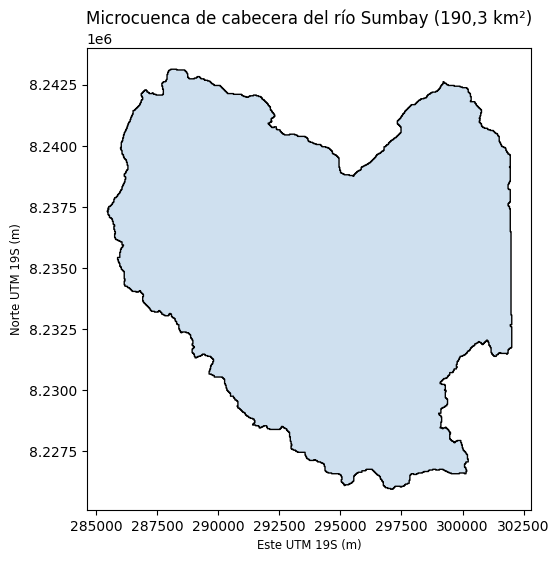

In [72]:
ax = cuenca.plot(color="#cfe0ef", edgecolor="black", figsize=(6, 6))
ax.set_title("Microcuenca de cabecera del río Sumbay (190,3 km²)")
ax.set_xlabel("Este UTM 19S (m)"); ax.set_ylabel("Norte UTM 19S (m)")
plt.show()

In [73]:
# la malla: el recuadro de la cuenca con 300 m de margen
x0, y0, x1, y1 = cuenca.total_bounds #la malla solo abarca la cuenca.
x0, y0, x1, y1 = x0 - 300, y0 - 300, x1 + 300, y1 + 300
ncol = int((x1 - x0) / RES)
nfil = int((y1 - y0) / RES)
transform = from_origin(x0, y1, RES, RES)

def a_la_malla(url, metodo):
    """Lee un ráster y lo lleva a la malla de trabajo."""
    destino = np.zeros((nfil, ncol), dtype="float32")
    with rasterio.open(url) as src:
        reproject(rasterio.band(src, 1), destino,
                  dst_transform=transform, dst_crs=UTM, resampling=metodo)
    return destino

# DEM: bilinear promedia vecinos -> correcto para un valor continuo como la altitud
dem = a_la_malla(F_DEM, Resampling.bilinear)

# Cobertura: mode toma la clase más frecuente -> las clases (30, 60, 80...) son etiquetas, no se promedian
cobertura = a_la_malla(F_COBER, Resampling.mode).astype("uint8")

en_cuenca = features.rasterize(cuenca.geometry, out_shape=dem.shape, transform=transform).astype(bool)
extent = (x0, x0 + ncol * RES, y1 - nfil * RES, y1)

def guardar_tif(arreglo, nombre, tipo="float32"):
    perfil = dict(driver="GTiff", height=nfil, width=ncol, count=1, dtype=tipo,
                  crs=UTM, transform=transform, nodata=-9999 if tipo == "float32" else 0)
    with rasterio.open(nombre, "w", **perfil) as dst:
        dst.write(arreglo.astype(tipo), 1)

guardar_tif(dem, "dem_utm.tif")
print(f"Malla: {nfil} filas x {ncol} columnas · altitud {dem[en_cuenca].min():.0f} a {dem[en_cuenca].max():.0f} m")

Malla: 592 filas x 571 columnas · altitud 4489 a 5033 m


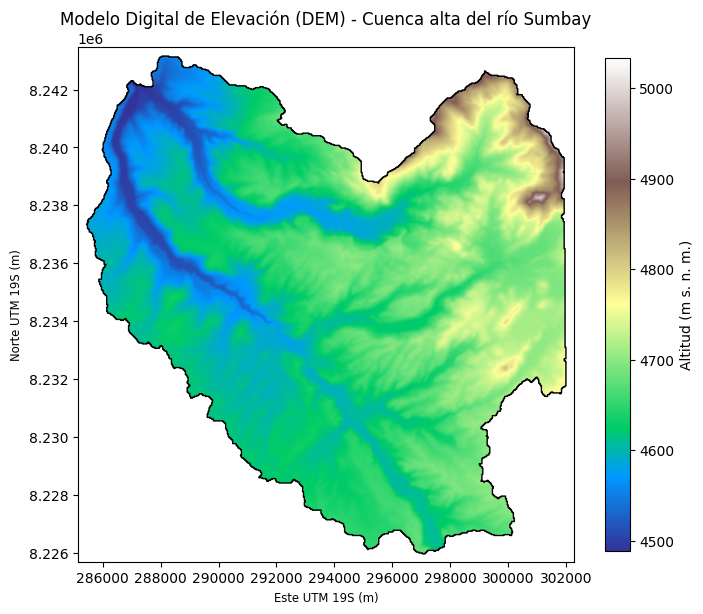

In [74]:
#veamos el dem_utm.tif (ruta relativa: funciona en Colab, donde la carpeta de trabajo es /content)
with rasterio.open("dem_utm.tif") as src:
  #plotear el raster
  dem_data = np.where(en_cuenca, src.read(1), np.nan)   # solo dentro de la cuenca
  plt.figure(figsize=(8, 8))
  plt.imshow(dem_data, cmap='terrain', extent=extent)
  plt.colorbar(label='Altitud (m s. n. m.)', shrink=0.8)
  cuenca.boundary.plot(ax=plt.gca(), color="black", lw=1)
  plt.title('Modelo Digital de Elevación (DEM) - Cuenca alta del río Sumbay')
  plt.xlabel('Este UTM 19S (m)')
  plt.ylabel('Norte UTM 19S (m)')
  plt.show()

## 3. Procesamiento

### 3.1 ¿Cuándo tocar la campana? Pronóstico → escorrentía → nivel de alerta

El pronóstico de Open-Meteo se pide para **un solo punto**, el centroide de la cuenca, y se toma como si fuera la lluvia media de toda la cuenca. Si no hay conexión, se usa como escenario el evento de la semana 8 (**24,8 mm**).

In [75]:
# centroide de la cuenca en grados: el punto donde pido el pronóstico
centro = cuenca.to_crs("EPSG:4326").geometry.union_all().centroid if hasattr(cuenca.geometry, "union_all") \
         else cuenca.to_crs("EPSG:4326").unary_union.centroid
LAT, LON = round(centro.y, 3), round(centro.x, 3)
print(f"Centroide de la cuenca: lat {LAT}, lon {LON}")

Centroide de la cuenca: lat -15.955, lon -70.922


In [76]:
#paso 1 pronostico de open-meteo por punto para tomar este punto como si fuera el promedio de la cuenca.
PRONOSTICO_MM = 24.8   # escenario de respaldo: evento de la semana 8 (se usa si no hay conexión)
try:
    import requests
    r = requests.get("https://api.open-meteo.com/v1/forecast", timeout=15, params={
        "latitude": LAT, "longitude": LON, "daily": "precipitation_sum",
        "forecast_days": 2, "timezone": "America/Lima"}).json()
    display(pd.DataFrame(r["daily"]))
    PRONOSTICO_MM = sum(r["daily"]["precipitation_sum"])
    print(f"Pronóstico real para 48 h: {PRONOSTICO_MM:.1f} mm")
except Exception:
    print(f"Sin conexión con Open-Meteo; se usa el escenario de {PRONOSTICO_MM} mm")

,time,precipitation_sum
0,2026-11-05,0.1
1,2026-11-06,15.0


Pronóstico real para 48 h: 15.1 mm


In [77]:
#paso 1 (opcional): para probar el sistema con una tormenta, quito el # y pongo la lluvia que quiera
#PRONOSTICO_MM = 90 #Valor para prueba o valor que viene de un pronóstico
print(PRONOSTICO_MM)

15.1


In [78]:
#paso 2 escorrentia
CN_CUENCA = 87.5 #ya lo calculamos la semana 8 para nuestra cuenca (CN medio actual).

#cortes en mm de escorrentía (mismos umbrales de la práctica)
CORTES = [(50, "ROJO"), (25, "ANARANJADO"), (10, "AMARILLO"), (0, "VERDE")]

def escorrentia(P, CN=CN_CUENCA):
    S = 25400 / CN - 254          # retención potencial máxima (mm)
    Ia = 0.2 * S                  # abstracción inicial: lo que se queda antes de escurrir
    return np.where(P > Ia, (P - Ia) ** 2 / (P + 0.8 * S), 0)

def nivel(Q):
    return next(n for corte, n in CORTES if Q >= corte)

area_km2 = cuenca.area.sum() / 1e6
Q = float(escorrentia(PRONOSTICO_MM))
volumen = Q / 1000 * area_km2 * 1e6                     # mm -> m, por el área en m²
print(f"Lluvia pronosticada: {PRONOSTICO_MM:.1f} mm")
print(f"Escorrentía esperada: {Q:.1f} mm ({Q / PRONOSTICO_MM if PRONOSTICO_MM > 0 else 0:.0%} de la lluvia)")
print(f"Volumen que llega al río: {volumen / 1e6:.2f} millones de m³")
print(f"Nivel: {nivel(Q)}")

Lluvia pronosticada: 15.1 mm
Escorrentía esperada: 1.4 mm (9% de la lluvia)
Volumen que llega al río: 0.27 millones de m³
Nivel: VERDE


> **Nota.** Con un CN único de 87,5, el evento de 24,8 mm da unos 5,7 mm de escorrentía. En la semana 8 obtuve 7,0 mm porque allí calculé la escorrentía **celda por celda** y después promedié. Las dos formas son válidas: aquí se usa el CN único porque el SAT necesita una respuesta rápida para toda la cuenca.

In [79]:
#la ecuación de escorrentia al revés: ¿desde cuánta lluvia se activa cada nivel?
def lluvia_para(Q, CN=CN_CUENCA):
    """La ecuación al revés: lluvia (mm) que produce una escorrentía Q (mm)."""
    S = 25400 / CN - 254
    return 0.2 * S + (Q + (Q**2 + 4 * Q * S) ** 0.5) / 2

umbrales = pd.DataFrame({"nivel": ["AMARILLO", "ANARANJADO", "ROJO"],
                         "escorrentía desde (mm)": [10, 25, 50],
                         "lluvia Sumbay, CN 87,5 (mm)": [round(lluvia_para(q)) for q in (10, 25, 50)],
                         "lluvia Atitlán, CN 77,5 (mm)": [round(lluvia_para(q, 77.5)) for q in (10, 25, 50)]})
umbrales.to_csv(f"{SALIDA}/S09_umbrales_alerta_sumbay.csv", index=False)
umbrales

,nivel,escorrentía desde (mm),"lluvia Sumbay, CN 87,5 (mm)","lluvia Atitlán, CN 77,5 (mm)"
0,AMARILLO,10,32,47
1,ANARANJADO,25,52,72
2,ROJO,50,82,105


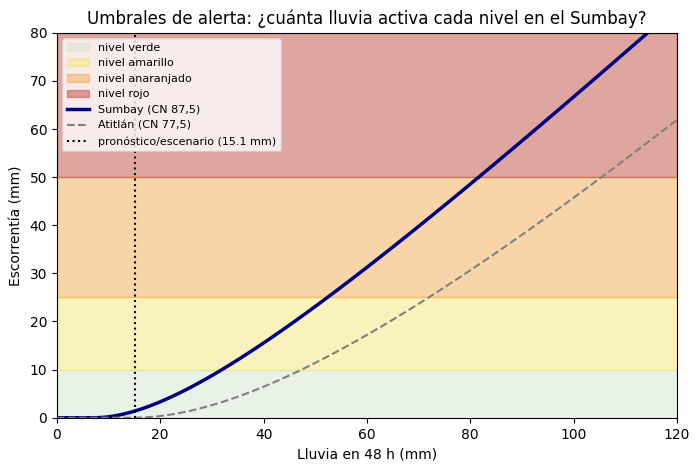

In [80]:
# Gráfico de la curva lluvia–escorrentía con las bandas del semáforo de alerta
P = np.arange(0, 121)
fig, ax = plt.subplots(figsize=(8, 5))
for (q0, q1, c, n) in [(0, 10, "#CFE3C9", "verde"), (10, 25, "#F2E36B", "amarillo"),
                       (25, 50, "#F0A040", "anaranjado"), (50, 80, "#B83A2E", "rojo")]:
    ax.axhspan(q0, q1, color=c, alpha=0.45, label=f"nivel {n}")
ax.plot(P, escorrentia(P), color="navy", lw=2.5, label="Sumbay (CN 87,5)")
ax.plot(P, escorrentia(P, 77.5), color="gray", lw=1.5, ls="--", label="Atitlán (CN 77,5)")
ax.axvline(PRONOSTICO_MM, color="black", ls=":", label=f"pronóstico/escenario ({PRONOSTICO_MM:.1f} mm)")
ax.set_xlim(0, 120); ax.set_ylim(0, 80)
ax.set_xlabel("Lluvia en 48 h (mm)"); ax.set_ylabel("Escorrentía (mm)")
ax.set_title("Umbrales de alerta: ¿cuánta lluvia activa cada nivel en el Sumbay?")
ax.legend(loc="upper left", fontsize=8)
plt.show()

### 3.2 ¿A qué puertas ir a tocar? Amenaza, vulnerabilidad y riesgo

In [81]:
#paso 3 la amenaza es mayor entre más cerca está del cauce y con menor pendiente
grid = Grid.from_raster("dem_utm.tif")
dem_g = grid.read_raster("dem_utm.tif")
dem_lleno = grid.resolve_flats(grid.fill_depressions(grid.fill_pits(dem_g)))
direccion = grid.flowdir(dem_lleno)
acumulacion = np.array(grid.accumulation(direccion))

cauce = (acumulacion > 1000) & en_cuenca          # 1 000 celdas ≈ 0.9 km² de área aportante, dentro de la cuenca
dist_cauce = ndimage.distance_transform_edt(~cauce) * RES   # metros hasta el cauce más cercano

gy, gx = np.gradient(dem, RES)
pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))       # grados
print(f"Celdas de cauce: {cauce.sum():,} · pendiente media de la cuenca: {pendiente[en_cuenca].mean():.1f}°")

Celdas de cauce: 4,367 · pendiente media de la cuenca: 5.6°


#### Amenaza de inundación de 1 a 5

El agua de una crecida ocupa el terreno **cercano al cauce** y **plano**. Cada condición se reclasifica de 1 a 5:

| Puntaje | Distancia al cauce | Pendiente |
|---|---|---|
| 5 | < 50 m | < 2° |
| 4 | 50–100 m | 2–5° |
| 3 | 100–200 m | 5–10° |
| 2 | 200–400 m | 10–20° |
| 1 | > 400 m | > 20° |

Como se necesitan **las dos condiciones a la vez**, la amenaza es el **menor** de los dos puntajes: un terreno plano pero lejos del río no se inunda, y uno junto al río pero empinado tampoco.

In [82]:
p_cauce = np.select([dist_cauce < 50, dist_cauce < 100, dist_cauce < 200, dist_cauce < 400], [5, 4, 3, 2], default=1)
p_plano = np.select([pendiente < 2, pendiente < 5, pendiente < 10, pendiente < 20], [5, 4, 3, 2], default=1)
amenaza = np.minimum(p_cauce, p_plano)

ha = RES * RES / 1e4                                   # una celda de 30 m = 0,09 ha
tabla_amenaza = pd.DataFrame({"amenaza": [1, 2, 3, 4, 5],
                              "area_ha": [(amenaza[en_cuenca] == k).sum() * ha for k in range(1, 6)]})
tabla_amenaza["%_cuenca"] = 100 * tabla_amenaza.area_ha / tabla_amenaza.area_ha.sum()
tabla_amenaza.round(1)

,amenaza,area_ha,%_cuenca
0,1,8897.0,46.7
1,2,5589.9,29.4
2,3,2614.6,13.7
3,4,1263.5,6.6
4,5,672.0,3.5


In [83]:
# Comprobación de unidades: 190,3 km² = 19 030 ha
area_total_ha = en_cuenca.sum() * ha
alta_ha = (amenaza[en_cuenca] >= 4).sum() * ha
print(f"Cuenca: {area_total_ha:,.0f} ha · amenaza alta (4 y 5): {alta_ha:,.0f} ha ({alta_ha / area_total_ha:.0%})")

Cuenca: 19,037 ha · amenaza alta (4 y 5): 1,936 ha (10%)


#### Vulnerabilidad adaptada a la puna

La tabla del profesor está pensada para Atitlán, donde hay pueblos y cultivos. En la cabecera del Sumbay **WorldCover no detecta áreas construidas ni cultivos**. Lo que se daña con una crecida es el **sustento ganadero**: pastos para alpacas y llamas, estancias y corrales junto al río.

| Clase WorldCover | Cobertura en el Sumbay | Vulnerabilidad | Por qué |
|---|---|---|---|
| 50 | Construido (estancias, vías) | 5 | Personas e infraestructura |
| 30 | Pastizal (pajonal) | 3 | Pastoreo; allí están las estancias y los corrales |
| 90 | Bofedal / humedal herbáceo | 2 | Forraje clave en estiaje, pero adaptado al anegamiento |
| 60 | Vegetación rala / suelo desnudo | 1 | Poco que perder |
| 80 | Agua | 1 | Ya es agua |

> **Limitación.** Una estancia de 10 × 10 m es más pequeña que una celda de 30 m, así que WorldCover no la ve. Por eso el resultado sirve para encontrar **zonas a vigilar**, no para contar viviendas.

In [84]:
#calculo de la vulnerabilidad (adaptada a la cabecera altoandina)
vulnerabilidad = np.select(
    [cobertura == 50,                       # construido
     cobertura == 30,                       # pastizal: pastoreo de alpacas y llamas
     cobertura == 90],                      # bofedal / humedal herbáceo
    [5, 3, 2], default=1)                   # vegetación rala, agua y otros: 1

nombres_cob = {30: "Pastizal", 50: "Construido", 60: "Vegetación rala / suelo desnudo", 80: "Agua", 90: "Bofedal / humedal"}
v_por_clase = {50: 5, 30: 3, 90: 2, 60: 1, 80: 1}
tabla_cob = pd.DataFrame([{"clase": k, "cobertura": n, "vulnerabilidad": v_por_clase[k],
                           "area_ha": ((cobertura == k) & en_cuenca).sum() * ha} for k, n in nombres_cob.items()])
tabla_cob["%_cuenca"] = 100 * tabla_cob.area_ha / tabla_cob.area_ha.sum()
tabla_cob.round(1)

,clase,cobertura,vulnerabilidad,area_ha,%_cuenca
0,30,Pastizal,3,6264.4,32.9
1,50,Construido,5,0.0,0.0
2,60,Vegetación rala / suelo desnudo,1,11822.8,62.1
3,80,Agua,1,948.3,5.0
4,90,Bofedal / humedal,2,1.4,0.0


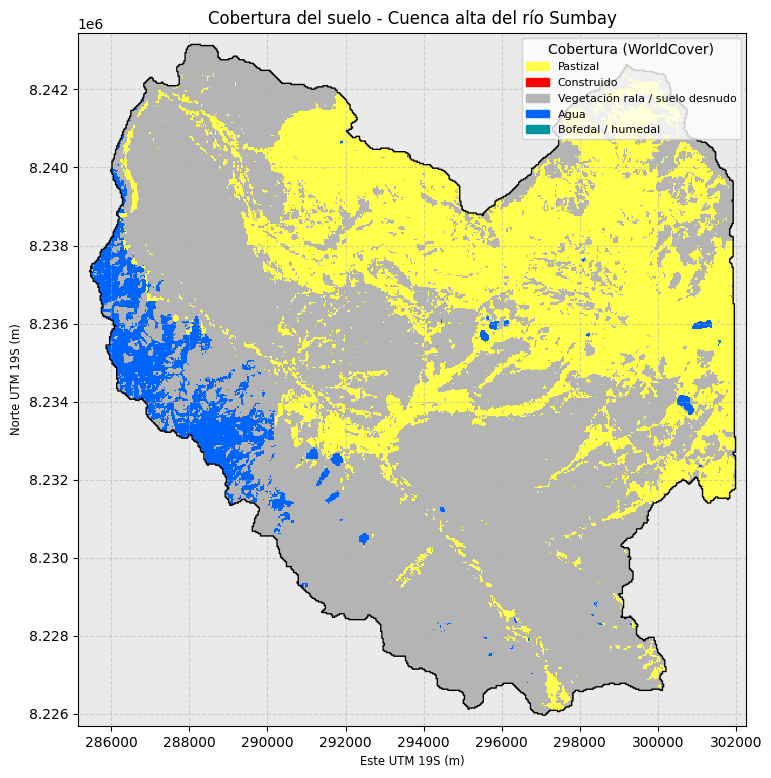

In [85]:
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

# Categorías de WorldCover presentes en el Sumbay y sus colores oficiales
categorias = {
    30: ("Pastizal", "#ffff4c"),
    50: ("Construido", "#fa0000"),
    60: ("Vegetación rala / suelo desnudo", "#b4b4b4"),
    80: ("Agua", "#0064ff"),
    90: ("Bofedal / humedal", "#0096a0")
}

# Enmascarar la cobertura únicamente para la zona dentro de la cuenca
cobertura_cuenca = np.where(en_cuenca, cobertura, 0)

# Crear un mapa de colores discreto
valores_unicos = sorted(categorias.keys())
colores = [categorias[val][1] for val in valores_unicos]

# Añadimos el fondo (valor 0) como gris claro
cmap_custom = mcolors.ListedColormap(["#eaeaea"] + colores)
bounds = [0] + valores_unicos + [100]
norm = mcolors.BoundaryNorm(bounds, cmap_custom.N)

# Graficar
plt.figure(figsize=(9, 9))
img = plt.imshow(cobertura_cuenca, cmap=cmap_custom, norm=norm, extent=extent, interpolation="nearest")
cuenca.boundary.plot(ax=plt.gca(), color="black", lw=1)

# Crear parches para la leyenda
parches = [mpatches.Patch(color=categorias[val][1], label=categorias[val][0]) for val in valores_unicos]
plt.legend(handles=parches, loc="upper right", title="Cobertura (WorldCover)", fontsize=8)

plt.title("Cobertura del suelo - Cuenca alta del río Sumbay")
plt.xlabel("Este UTM 19S (m)")
plt.ylabel("Norte UTM 19S (m)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [86]:
#paso 4 calculo de riesgo, semaforo
riesgo = amenaza * vulnerabilidad

#el semáforo es categorizar ese riesgo (mismos cortes de la práctica)
semaforo = np.select([riesgo >= 16, riesgo >= 6], [3, 2], default=1)    # 1 bajo, 2 medio, 3 alto
print("Riesgo máximo dentro de la cuenca:", riesgo[en_cuenca].max())

Riesgo máximo dentro de la cuenca: 15


In [87]:
#estimar en hectareas los riesgos de la cuenca, y qué cobertura hay en cada nivel
resumen = pd.DataFrame({"riesgo": ["bajo (1–5)", "medio (6–15)", "alto (16–25)"],
                        "area_ha": [(semaforo[en_cuenca] == k).sum() * ha for k in (1, 2, 3)],
                        "pastizal_ha": [((semaforo == k) & (cobertura == 30) & en_cuenca).sum() * ha for k in (1, 2, 3)],
                        "bofedal_ha": [((semaforo == k) & (cobertura == 90) & en_cuenca).sum() * ha for k in (1, 2, 3)],
                        "construido_ha": [((semaforo == k) & (cobertura == 50) & en_cuenca).sum() * ha for k in (1, 2, 3)]})
resumen["%_cuenca"] = 100 * resumen.area_ha / resumen.area_ha.sum()
resumen.round(1)

,riesgo,area_ha,pastizal_ha,bofedal_ha,construido_ha,%_cuenca
0,bajo (1–5),15385.0,2613.3,0.4,0.0,80.8
1,medio (6–15),3652.1,3651.1,1.0,0.0,19.2
2,alto (16–25),0.0,0.0,0.0,0.0,0.0


## 4. Visualización

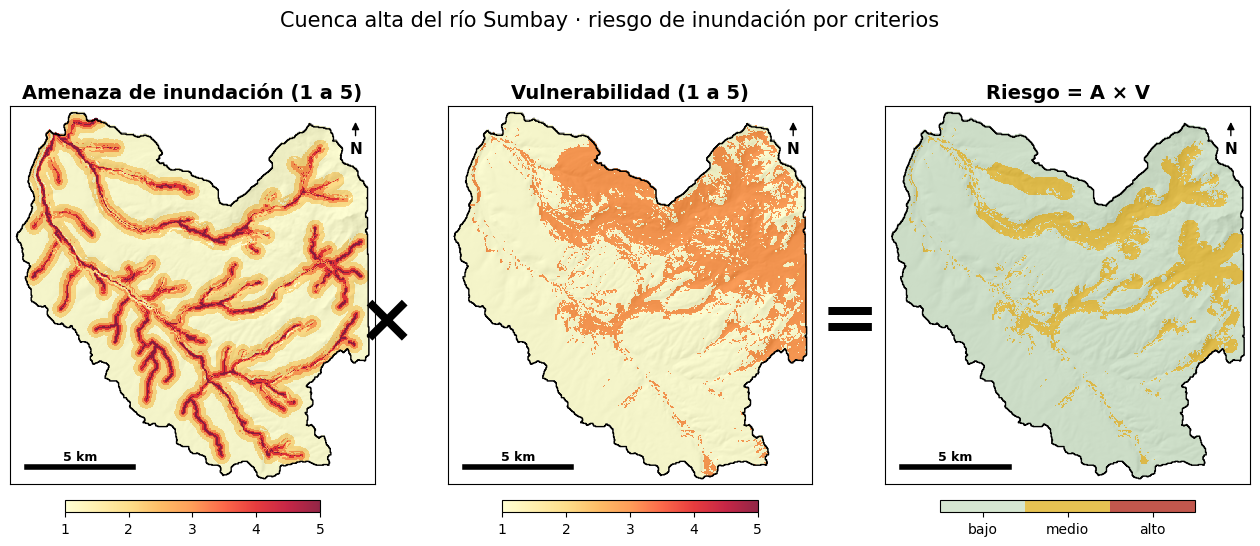

In [88]:
from matplotlib.colors import ListedColormap, LightSource
from matplotlib.patches import Patch
sombra = LightSource(315, 40).hillshade(dem, vert_exag=2, dx=RES, dy=RES)
colores_semaforo = ListedColormap(["#CFE3C9", "#E3B935", "#B83A2E"])

def barra_escala(ax, km=5):
    """Dibuja una barra de escala de `km` kilómetros en la esquina inferior izquierda."""
    xa, ya = extent[0] + 800, extent[2] + 800
    ax.plot([xa, xa + km * 1000], [ya, ya], color="black", lw=4)
    ax.text(xa + km * 500, ya + 350, f"{km} km", ha="center", fontsize=9, fontweight="bold")
    ax.annotate("N", xy=(extent[1] - 900, extent[3] - 600), xytext=(extent[1] - 900, extent[3] - 2200),
                ha="center", fontsize=11, fontweight="bold", arrowprops=dict(arrowstyle="-|>", color="black"))

fig, axs = plt.subplots(1, 3, figsize=(16, 6.5))
capas = [(amenaza, "Amenaza de inundación (1 a 5)", "YlOrRd", 1, 5), (vulnerabilidad, "Vulnerabilidad (1 a 5)", "YlOrRd", 1, 5),
         (semaforo, "Riesgo = A × V", colores_semaforo, 0.5, 3.5)]
for ax, (arr, t, cm, v0, v1) in zip(axs, capas):
    ax.imshow(np.where(en_cuenca, sombra, np.nan), cmap="gray", extent=extent)
    im = ax.imshow(np.where(en_cuenca, arr, np.nan), cmap=cm, vmin=v0, vmax=v1, alpha=0.85, extent=extent, interpolation="nearest")
    cuenca.boundary.plot(ax=ax, color="black", lw=1)
    ax.set_title(t, fontsize=14, fontweight="bold"); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
    if t != "Riesgo = A × V":
        fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.03, ticks=[1, 2, 3, 4, 5])
    else:   # el semáforo lleva su propia barra con nombres en vez de números
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", shrink=0.7, pad=0.03, ticks=[1, 2, 3])
        cb.ax.set_xticklabels(["bajo", "medio", "alto"])
    barra_escala(ax)
fig.text(0.36, 0.5, "×", fontsize=50, ha="center", va="center", fontweight="bold")
fig.text(0.65, 0.5, "=", fontsize=50, ha="center", va="center", fontweight="bold")
fig.suptitle("Cuenca alta del río Sumbay · riesgo de inundación por criterios", fontsize=15)
plt.show()

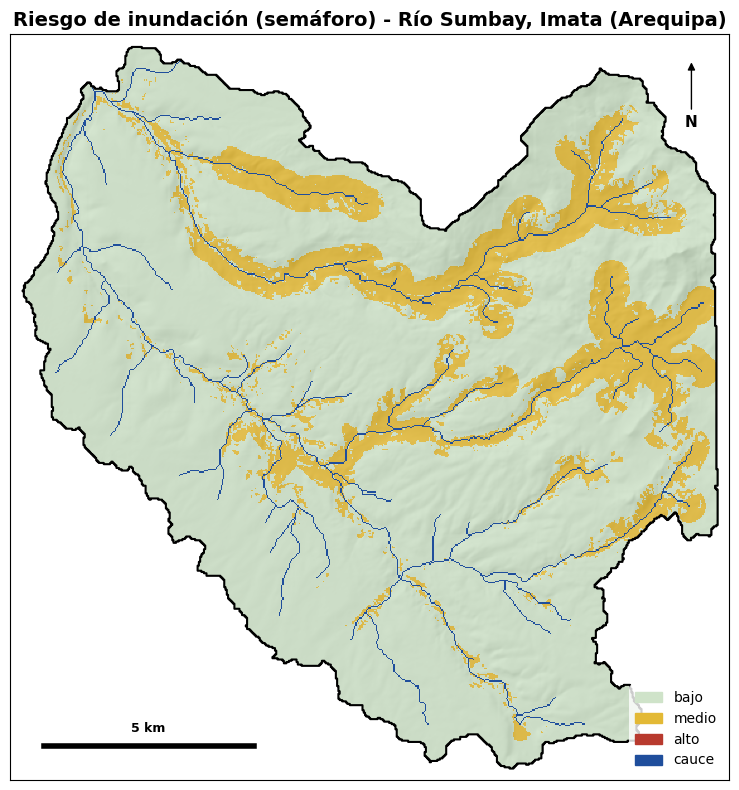

In [89]:
fig, ax = plt.subplots(figsize=(8, 8))

# Dibujar el relieve sombreado como base de fondo
ax.imshow(np.where(en_cuenca, sombra, np.nan), cmap="gray", extent=extent)

# Dibujar la capa de riesgo (semaforo)
im = ax.imshow(np.where(en_cuenca, semaforo, np.nan), cmap=colores_semaforo, vmin=0.5, vmax=3.5, alpha=0.85, extent=extent, interpolation="nearest")

# Dibujar el cauce principal y el límite de la cuenca
ax.imshow(np.where(cauce, 1, np.nan), cmap=ListedColormap(["#1f4e9c"]), extent=extent, interpolation="nearest")
cuenca.boundary.plot(ax=ax, color="black", lw=1.5)
barra_escala(ax)

# Configuración de títulos y ejes
ax.set_title("Riesgo de inundación (semáforo) - Río Sumbay, Imata (Arequipa)", fontsize=14, fontweight="bold")
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

# Agregar leyenda de colores personalizada
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(["#CFE3C9", "#E3B935", "#B83A2E", "#1f4e9c"],
                                                           ["bajo", "medio", "alto", "cauce"])],
          loc="lower right", frameon=True, facecolor="white", edgecolor="none")

plt.tight_layout()
plt.show()

### Lugares a vigilar y mensaje de alerta

Si hay celdas en **riesgo alto**, esas son el foco. En el Sumbay no las hay (no hay construido), así que el foco pasa a las celdas con **riesgo ≥ 12**: pastizal (V = 3) con amenaza 4 o 5, es decir, pastos planos junto al río. Las celdas se agrupan en bloques de ~1 km y a cada bloque se le busca un nombre en OpenStreetMap.

In [90]:
#identificar lugares basados en sus coordenadas
import time
import requests

def lugar_cercano(lat, lon):
    """Nombre del caserío, anexo o lugar en (lat, lon), según OpenStreetMap."""
    try:
        r = requests.get("https://nominatim.openstreetmap.org/reverse",
                         params={"lat": lat, "lon": lon, "format": "jsonv2", "zoom": 14, "accept-language": "es"},
                         headers={"User-Agent": "curso-CATIE-MCHV502"}, timeout=20)
        a = r.json().get("address", {})
        #print(a) #para ver todo el registro de la base de ubicacion
    except Exception:
        return "sin respuesta", "", "", ""
    time.sleep(1)                                    # regla de Nominatim: una consulta por segundo
    # en la puna casi no hay barrios: se agregan anexos, estancias, lugares y ríos
    lugar = next((a[k] for k in ["hamlet", "village", "isolated_dwelling", "farm", "locality", "neighbourhood",
                                  "suburb", "town", "city", "road", "water", "natural"] if k in a), "sin nombre")
    print(lugar)
    municipio = a.get("municipality") or a.get("city") or a.get("town") or a.get("county", "")
    #definir state como state o province
    state = a.get("state") or a.get("province") or a.get("region", "")
    pais = a.get("country", "")
    return lugar, municipio, state, pais

In [91]:
print(lugar_cercano(LAT, LON))   # prueba con el centroide de la cuenca

San Juan de Tarucani
('San Juan de Tarucani', 'San Juan de Tarucani', 'Arequipa', 'Perú')


In [92]:
foco = (semaforo == 3) & en_cuenca            # riesgo alto dentro de la cuenca
criterio = "riesgo alto"
if foco.sum() == 0:                           # en el Sumbay no hay riesgo alto: se vigila el riesgo medio-alto
    foco = (riesgo >= 12) & en_cuenca
    criterio = "riesgo ≥ 12 (pastizal con amenaza 4–5)"
BLOQUE = 34      # celdas de 30 m: bloques de ~1 km

filas, cols = np.nonzero(foco)
bloques = pd.DataFrame({"bf": filas // BLOQUE, "bc": cols // BLOQUE, "fila": filas, "col": cols})
bloques = bloques.groupby(["bf", "bc"]).agg(fila=("fila", "mean"), col=("col", "mean"), celdas=("fila", "size")).reset_index()
bloques = bloques[bloques.celdas >= 20].sort_values("celdas", ascending=False).head(15)   # ≥ 1,8 ha; los 15 mayores

x, y = rasterio.transform.xy(transform, bloques.fila.values, bloques.col.values)
centros = gpd.GeoSeries(gpd.points_from_xy(x, y), crs=UTM).to_crs("EPSG:4326")
bloques["lat"] = centros.y.round(5).values
bloques["lon"] = centros.x.round(5).values
bloques["area_ha"] = (bloques.celdas * ha).round(1)
print(f"{foco.sum() * ha:.0f} ha con {criterio}; se consultan los {len(bloques)} bloques mayores...")

nombres = [lugar_cercano(la, lo) for la, lo in zip(bloques.lat, bloques.lon)]
# si OpenStreetMap no da nombre, el bloque se llama por su número (el mismo del mapa)
bloques["lugar"] = [n[0] if n[0] not in ("sin respuesta", "sin nombre") else f"Zona {i}"
                    for i, n in enumerate(nombres, start=1)]
bloques["municipio"] = [n[1] for n in nombres]

lugares = (bloques.groupby(["lugar", "municipio"])
           .agg(area_a_vigilar_ha=("area_ha", "sum"), lat=("lat", "mean"), lon=("lon", "mean"))
           .round({"area_a_vigilar_ha": 1, "lat": 4, "lon": 4})
           .sort_values("area_a_vigilar_ha", ascending=False).reset_index())
lugares

841 ha con riesgo ≥ 12 (pastizal con amenaza 4–5); se consultan los 15 bloques mayores...
Toriane
Toriane
Cacahuasi
Pucatara
Cacahuasi
Pucalacala
San Juan de Tarucani
San Juan de Tarucani
San Juan de Tarucani
San Juan de Tarucani
Pucatara
Toriane
San Juan de Tarucani
Pucacancha
Pucacancha


,lugar,municipio,area_a_vigilar_ha,lat,lon
0,Toriane,San Juan de Tarucani,107.6,-15.9522,-70.8634
1,San Juan de Tarucani,San Juan de Tarucani,100.0,-15.9645,-70.8992
2,Cacahuasi,,54.6,-15.9346,-70.9109
3,Pucatara,,48.8,-15.9306,-70.9308
4,Pucacancha,San Juan de Tarucani,33.3,-15.9663,-70.9028
5,Pucalacala,,21.9,-15.9137,-70.9356


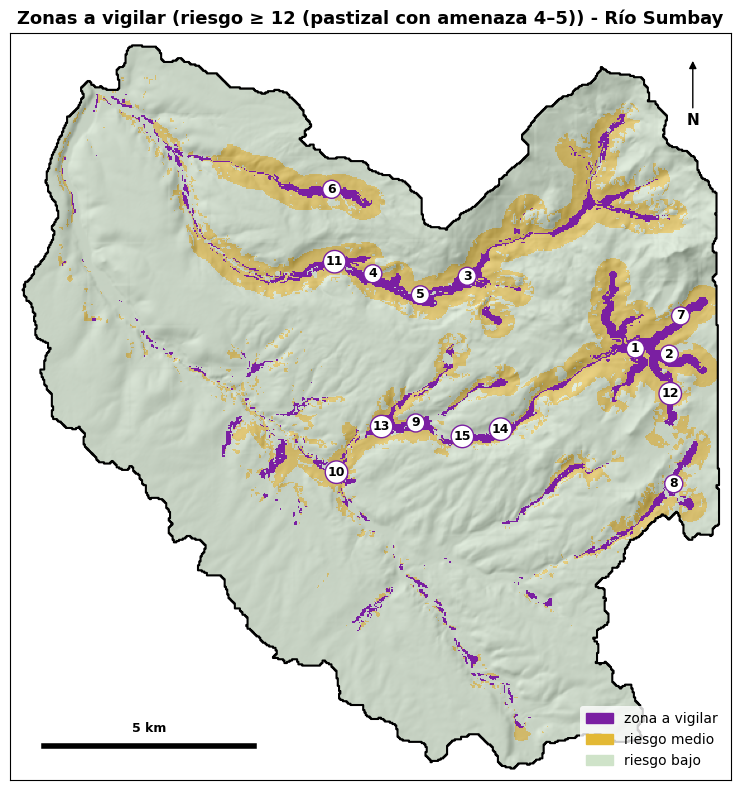

In [93]:
# Mapa de los bloques a vigilar sobre el semáforo
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(np.where(en_cuenca, sombra, np.nan), cmap="gray", extent=extent)
ax.imshow(np.where(en_cuenca, semaforo, np.nan), cmap=colores_semaforo, vmin=0.5, vmax=3.5, alpha=0.6, extent=extent, interpolation="nearest")
ax.imshow(np.where(foco, 1, np.nan), cmap=ListedColormap(["#7a1fa2"]), extent=extent, interpolation="nearest")
cuenca.boundary.plot(ax=ax, color="black", lw=1.5)
for i, (xx, yy) in enumerate(zip(x, y), start=1):
    ax.annotate(str(i), (xx, yy), color="black", fontsize=9, fontweight="bold", ha="center",
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="#7a1fa2"))
barra_escala(ax)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(""); ax.set_ylabel("")
ax.set_title(f"Zonas a vigilar ({criterio}) - Río Sumbay", fontsize=13, fontweight="bold")
ax.legend(handles=[Patch(color="#7a1fa2", label="zona a vigilar"),
                   Patch(color="#E3B935", label="riesgo medio"), Patch(color="#CFE3C9", label="riesgo bajo")],
          loc="lower right", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
plt.show()

In [94]:
lista = "\n".join(f"  - {r.lugar} ({r.municipio}): {r.area_a_vigilar_ha} ha a vigilar"
                  for r in lugares.head(6).itertuples())
aviso = f"""CUENCA ALTA DEL RÍO SUMBAY (IMATA) · INUNDACIÓN
Pronóstico: {PRONOSTICO_MM:.1f} mm en 48 horas
Escorrentía esperada: {Q:.1f} mm, unos {volumen / 1e6:.2f} millones de m³ hacia el río
Nivel: {nivel(Q)}
Umbrales: amarillo desde {lluvia_para(10):.0f} mm · anaranjado desde {lluvia_para(25):.0f} mm · rojo desde {lluvia_para(50):.0f} mm

Zonas a vigilar ({criterio}):
{lista}

Mapa de riesgo y umbrales calculados en clase; no es una alerta oficial."""
print(aviso)

CUENCA ALTA DEL RÍO SUMBAY (IMATA) · INUNDACIÓN
Pronóstico: 15.1 mm en 48 horas
Escorrentía esperada: 1.4 mm, unos 0.27 millones de m³ hacia el río
Nivel: VERDE
Umbrales: amarillo desde 32 mm · anaranjado desde 52 mm · rojo desde 82 mm

Zonas a vigilar (riesgo ≥ 12 (pastizal con amenaza 4–5)):
  - Toriane (San Juan de Tarucani): 107.6 ha a vigilar
  - San Juan de Tarucani (San Juan de Tarucani): 100.0 ha a vigilar
  - Cacahuasi (): 54.6 ha a vigilar
  - Pucatara (): 48.8 ha a vigilar
  - Pucacancha (San Juan de Tarucani): 33.3 ha a vigilar
  - Pucalacala (): 21.9 ha a vigilar

Mapa de riesgo y umbrales calculados en clase; no es una alerta oficial.


In [95]:
# Guardar los productos de la semana 9 (los usaré en el proyecto final)
guardar_tif(amenaza, f"{SALIDA}/S09_amenaza_sumbay.tif", "uint8")
guardar_tif(vulnerabilidad, f"{SALIDA}/S09_vulnerabilidad_sumbay.tif", "uint8")
guardar_tif(semaforo, f"{SALIDA}/S09_semaforo_riesgo_sumbay.tif", "uint8")
resumen.round(1).to_csv(f"{SALIDA}/S09_resumen_riesgo_sumbay.csv", index=False)
lugares.to_csv(f"{SALIDA}/S09_zonas_a_vigilar_sumbay.csv", index=False)
with open(f"{SALIDA}/S09_aviso_sumbay.txt", "w", encoding="utf-8") as f:
    f.write(aviso)
print(sorted(os.listdir(SALIDA)))

['S09_amenaza_sumbay.tif', 'S09_aviso_sumbay.txt', 'S09_resumen_riesgo_sumbay.csv', 'S09_semaforo_riesgo_sumbay.tif', 'S09_umbrales_alerta_sumbay.csv', 'S09_vulnerabilidad_sumbay.tif', 'S09_zonas_a_vigilar_sumbay.csv']


## 5. Interpretación (máx. 150 palabras)

Con un CN de 87,5, la capacidad de infiltracion del suelo y la escasa vegetacion, permiten que la cabecera del Sumbay responde rápido: bastan **32 mm en 48 h para la alerta amarilla y 82 mm para la roja**, unos 20 mm menos que en Atitlán,un CN de 77.5 . El evento de referencia lluvia media de la cuenca (24,8 mm) queda en verde y, a 7 mm del umbral amarillo.

La puna es plana (pendiente media 5,6°), por eso el **10 % de la cuenca (1 936 ha) tiene amenaza alta**, frente a 1,5 % en Atitlán: aquí la crecida se expande a los lados en vez de encajonarse.

No aparece riesgo alto porque WorldCover no detecta construcciones. El riesgo medio (19 %) se concentra en **841 ha de pastizal plano junto al río**, donde pastan alpacas y se ubican estancias y corrales. El resultado no significa que no haya peligro: indica que hace falta un inventario de campo de estancias, corrales y la vía, que el satélite no ve.

In [ ]:
# 6. Guardar notebook y resultados de la semana 9 en GitHub (carpeta T06_inundacion)
# Pide el token al ejecutar (no queda escrito en el cuaderno).
# Si guardaste un secreto GITHUB_TOKEN en Colab (icono de llave), lo usa directamente.
import os, base64, json, requests
from getpass import getpass
from google.colab import _message

try:
    from google.colab import userdata
    TOKEN = userdata.get("GITHUB_TOKEN")
except Exception:
    TOKEN = getpass("Token de GitHub (permiso Contents: lectura y escritura): ")

REPO = "lazaroninamiguel-dot/mchv502-cuencas"
CARPETA = "T06_inundacion"
API = f"https://api.github.com/repos/{REPO}/contents/"
H = {"Authorization": f"Bearer {TOKEN}", "Accept": "application/vnd.github+json"}
ETIQUETA = "(riesgo por inundación, cuenca de Sumbay)"

def subir(ruta_repo, contenido):
    """Crea el archivo en GitHub o lo actualiza si ya existe."""
    url = API + ruta_repo
    datos = {"message": f"T06: {os.path.basename(ruta_repo)} {ETIQUETA}",
             "content": base64.b64encode(contenido).decode(), "branch": "main"}
    previo = requests.get(url, headers=H, params={"ref": "main"})
    if previo.status_code == 200:
        datos["sha"] = previo.json()["sha"]
    r = requests.put(url, headers=H, json=datos)
    print("OK   " if r.ok else "ERROR", ruta_repo, "" if r.ok else r.text[:150])

# 1) Productos de la carpeta S09_riesgo
for nombre in sorted(os.listdir(SALIDA)):
    with open(os.path.join(SALIDA, nombre), "rb") as f:
        subir(f"{CARPETA}/resultados/{nombre}", f.read())

# 2) README de resultados
contenido_archivo = {
    "S09_amenaza_sumbay.tif": "Amenaza por inundación por celda",
    "S09_vulnerabilidad_sumbay.tif": "Vulnerabilidad por cobertura",
    "S09_semaforo_riesgo_sumbay.tif": "Riesgo = amenaza × vulnerabilidad, en clases de semáforo",
    "S09_resumen_riesgo_sumbay.csv": "Resumen de superficie por clase de riesgo",
    "S09_zonas_a_vigilar_sumbay.csv": "Lugares / bloques a vigilar",
    "S09_umbrales_alerta_sumbay.csv": "Umbrales de lluvia para cada nivel de alerta del SAT",
    "S09_aviso_sumbay.txt": "Texto del aviso del SAT",
}
filas = "\n".join(f"| `{n}` | {contenido_archivo.get(n, '')} |" for n in sorted(os.listdir(SALIDA)))
aviso = open(os.path.join(SALIDA, "S09_aviso_sumbay.txt"), encoding="utf-8").read()
readme = f"""# T06 · Riesgo por inundación (SAT) · microcuenca de cabecera del río Sumbay (Imata)

Resultados del cuaderno `S09_Inundacion_Sumbay_Lazaro_Miguel.ipynb` (semana 9). Malla de 30 m, EPSG:32719.

| Archivo | Contenido |
|---|---|
{filas}

## Aviso generado

```
{aviso}
```
"""
subir(f"{CARPETA}/resultados/README.md", readme.encode("utf-8"))

# 3) El propio cuaderno, con sus salidas y mapas
nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
subir(f"{CARPETA}/notebook/S09_Inundacion_Sumbay_Lazaro_Miguel.ipynb",
      json.dumps(nb, ensure_ascii=False, indent=1).encode("utf-8"))


OK    T06_inundacion/resultados/S09_amenaza_sumbay.tif 
OK    T06_inundacion/resultados/S09_aviso_sumbay.txt 
OK    T06_inundacion/resultados/S09_resumen_riesgo_sumbay.csv 
OK    T06_inundacion/resultados/S09_semaforo_riesgo_sumbay.tif 
OK    T06_inundacion/resultados/S09_umbrales_alerta_sumbay.csv 
OK    T06_inundacion/resultados/S09_vulnerabilidad_sumbay.tif 
OK    T06_inundacion/resultados/S09_zonas_a_vigilar_sumbay.csv 
